# Lab 1. Spectral Analysis of Deterministic Signals

**Variant 11**

Task: synthesize a discrete-time signal by using the IDFT in matrix notation for different values of $N$, show the matrices $\mathbf{W}$ and $\mathbf{K}$ and plot the synthesized signal.

$$\mathbf{x}_\mu = [6, 2, 4, 3, 4, 5, 0, 0, 0, 0]^\mathrm{T}$$

## IDFT in matrix notation

$$x[k] = \frac{1}{N}\sum_{\mu=0}^{N-1} X[\mu]\,\mathrm{e}^{+\mathrm{j}\frac{2\pi}{N}k\mu}, \qquad k = 0, \dots, N-1$$

With $\mathbf{x}_k = (x[0], \dots, x[N-1])^\mathrm{T}$ and $\mathbf{x}_\mu = (X[0], \dots, X[N-1])^\mathrm{T}$ the IDFT is

$$\mathbf{x}_k = \frac{1}{N}\,\mathbf{W}\,\mathbf{x}_\mu,$$

where

$$\mathbf{K} = \begin{bmatrix}0\\1\\\vdots\\N-1\end{bmatrix}\cdot\begin{bmatrix}0 & 1 & \cdots & N-1\end{bmatrix}, \qquad \mathbf{W} = \mathrm{e}^{+\mathrm{j}\frac{2\pi}{N}\odot\mathbf{K}}.$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import ifft
from pathlib import Path

np.set_printoptions(precision=3, suppress=True, linewidth=220)
plt.rcParams["figure.figsize"] = (9, 3.5)

figures = Path("out/figures")
figures.mkdir(parents=True, exist_ok=True)

In [2]:
X = np.array([6, 2, 4, 3, 4, 5, 0, 0, 0, 0])
N0 = len(X)
print("N0 =", N0)
print("x_mu =", X)

N0 = 10
x_mu = [6 2 4 3 4 5 0 0 0 0]


In [3]:
def fourier_matrices(N):
    k = np.arange(N)
    mu = np.arange(N)
    K = np.outer(k, mu)
    W = np.exp(+1j * 2 * np.pi / N * K)
    return K, W


def spectrum_of_length(X, N):
    XN = np.zeros(N, dtype=complex)
    m = min(N, len(X))
    XN[:m] = X[:m]
    return XN


def idft_matrix(X, N):
    K, W = fourier_matrices(N)
    XN = spectrum_of_length(X, N)
    x = 1 / N * W @ XN
    return x, K, W, XN

## Values of $N$

The last non-zero coefficient is $X[5]$, so the smallest length that keeps the whole spectrum is $N = 6$. The given vector has $N_0 = 10$ entries. For $N = 16$ and $N = 32$ the vector is extended with zeros.

| $N$ | $\mathbf{x}_\mu$ used |
|---|---|
| 6 | $[6, 2, 4, 3, 4, 5]$ |
| 10 | $[6, 2, 4, 3, 4, 5, 0, 0, 0, 0]$ |
| 16 | given vector + 6 zeros |
| 32 | given vector + 22 zeros |

In [4]:
N_values = [6, 10, 16, 32]
results = {N: idft_matrix(X, N) for N in N_values}

## Matrices $\mathbf{K}$ and $\mathbf{W}$

### $N = 6$

In [5]:
x6, K6, W6, X6 = results[6]
print("K =")
print(K6)
print()
print("W =")
print(W6)

K =
[[ 0  0  0  0  0  0]
 [ 0  1  2  3  4  5]
 [ 0  2  4  6  8 10]
 [ 0  3  6  9 12 15]
 [ 0  4  8 12 16 20]
 [ 0  5 10 15 20 25]]

W =
[[ 1. +0.j     1. +0.j     1. +0.j     1. +0.j     1. +0.j     1. +0.j   ]
 [ 1. +0.j     0.5+0.866j -0.5+0.866j -1. +0.j    -0.5-0.866j  0.5-0.866j]
 [ 1. +0.j    -0.5+0.866j -0.5-0.866j  1. -0.j    -0.5+0.866j -0.5-0.866j]
 [ 1. +0.j    -1. +0.j     1. -0.j    -1. +0.j     1. -0.j    -1. +0.j   ]
 [ 1. +0.j    -0.5-0.866j -0.5+0.866j  1. -0.j    -0.5-0.866j -0.5+0.866j]
 [ 1. +0.j     0.5-0.866j -0.5-0.866j -1. +0.j    -0.5+0.866j  0.5+0.866j]]


### $N = 10$

In [6]:
x10, K10, W10, X10 = results[10]
print("K =")
print(K10)
print()
print("Re(W) =")
print(W10.real)
print()
print("Im(W) =")
print(W10.imag)

K =
[[ 0  0  0  0  0  0  0  0  0  0]
 [ 0  1  2  3  4  5  6  7  8  9]
 [ 0  2  4  6  8 10 12 14 16 18]
 [ 0  3  6  9 12 15 18 21 24 27]
 [ 0  4  8 12 16 20 24 28 32 36]
 [ 0  5 10 15 20 25 30 35 40 45]
 [ 0  6 12 18 24 30 36 42 48 54]
 [ 0  7 14 21 28 35 42 49 56 63]
 [ 0  8 16 24 32 40 48 56 64 72]
 [ 0  9 18 27 36 45 54 63 72 81]]

Re(W) =
[[ 1.     1.     1.     1.     1.     1.     1.     1.     1.     1.   ]
 [ 1.     0.809  0.309 -0.309 -0.809 -1.    -0.809 -0.309  0.309  0.809]
 [ 1.     0.309 -0.809 -0.809  0.309  1.     0.309 -0.809 -0.809  0.309]
 [ 1.    -0.309 -0.809  0.809  0.309 -1.     0.309  0.809 -0.809 -0.309]
 [ 1.    -0.809  0.309  0.309 -0.809  1.    -0.809  0.309  0.309 -0.809]
 [ 1.    -1.     1.    -1.     1.    -1.     1.    -1.     1.    -1.   ]
 [ 1.    -0.809  0.309  0.309 -0.809  1.    -0.809  0.309  0.309 -0.809]
 [ 1.    -0.309 -0.809  0.809  0.309 -1.     0.309  0.809 -0.809 -0.309]
 [ 1.     0.309 -0.809 -0.809  0.309  1.     0.309 -0.809 -0.809  0.309]

For $N = 16$ and $N = 32$ the matrices are too large to print, so they are shown as images.

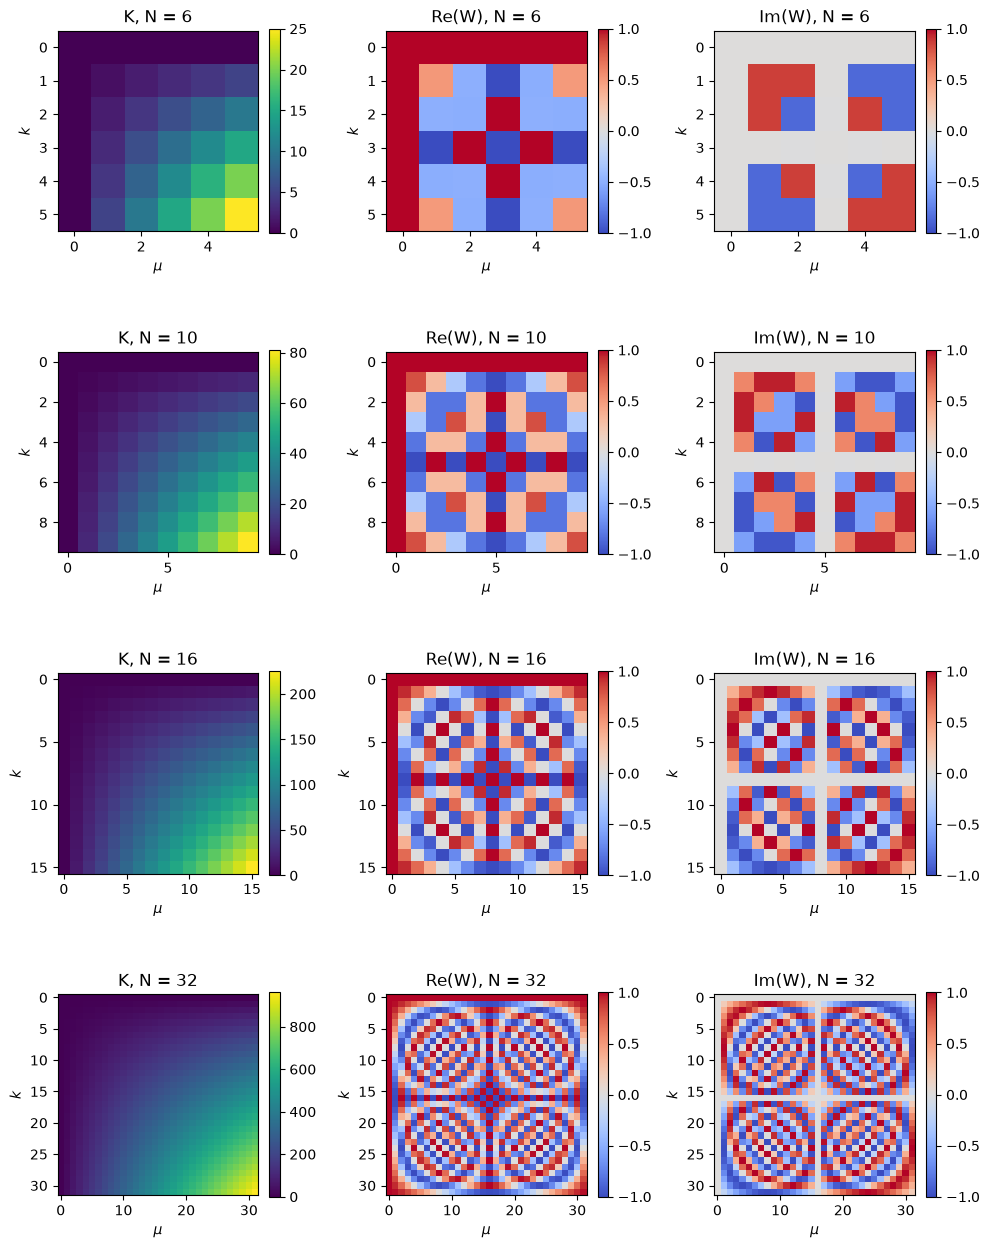

In [7]:
fig, ax = plt.subplots(len(N_values), 3, figsize=(10, 13))
for row, N in enumerate(N_values):
    _, K, W, _ = results[N]
    panels = [
        (K, "K", "viridis", None),
        (W.real, "Re(W)", "coolwarm", 1),
        (W.imag, "Im(W)", "coolwarm", 1),
    ]
    for col, (data, name, cmap, lim) in enumerate(panels):
        vmin = -lim if lim else None
        im = ax[row, col].imshow(data, cmap=cmap, vmin=vmin, vmax=lim)
        ax[row, col].xaxis.get_major_locator().set_params(integer=True)
        ax[row, col].yaxis.get_major_locator().set_params(integer=True)
        ax[row, col].set_title(f"{name}, N = {N}")
        ax[row, col].set_xlabel(r"$\mu$")
        ax[row, col].set_ylabel(r"$k$")
        fig.colorbar(im, ax=ax[row, col], fraction=0.046)
fig.tight_layout()
fig.savefig(figures / "matrices.png", dpi=150)
plt.show()

## Synthesis

Each signal is checked against `numpy.fft.ifft`.

In [8]:
for N in N_values:
    x, K, W, XN = results[N]
    print(f"N = {N:2d}  matches ifft: {np.allclose(x, ifft(XN))}")

print()
print("x[k] for N = 10:")
print(x10)

N =  6  matches ifft: True
N = 10  matches ifft: True
N = 16  matches ifft: True
N = 32  matches ifft: True

x[k] for N = 10:
[ 2.4  +0.j    -0.031+1.018j  0.719-0.131j  0.081+0.159j  0.831-0.213j  0.4  +0.j     0.831+0.213j  0.081-0.159j  0.719+0.131j -0.031-1.018j]


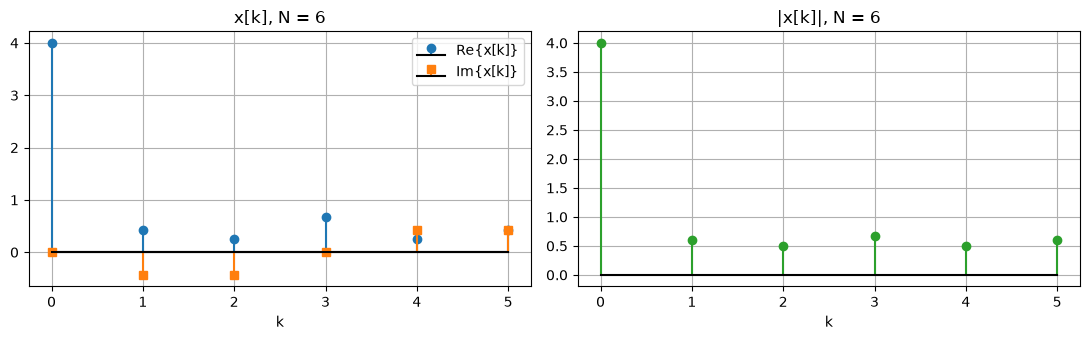

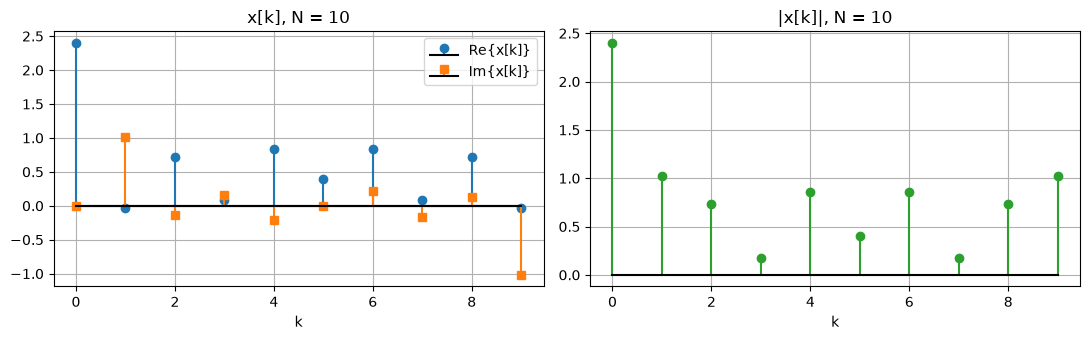

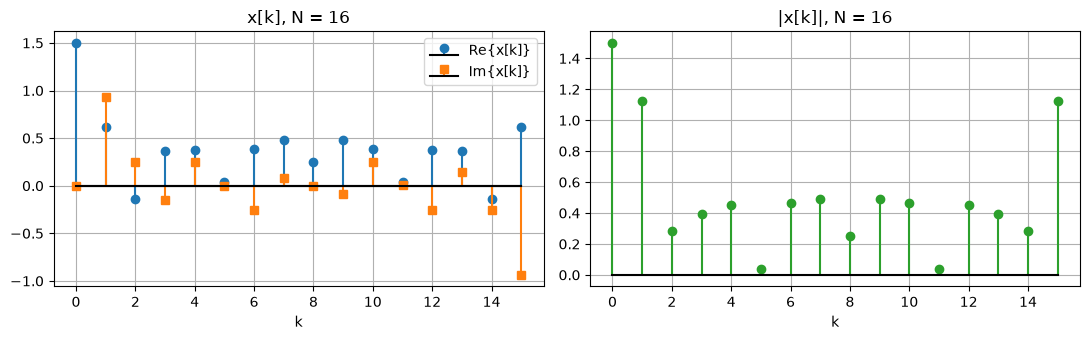

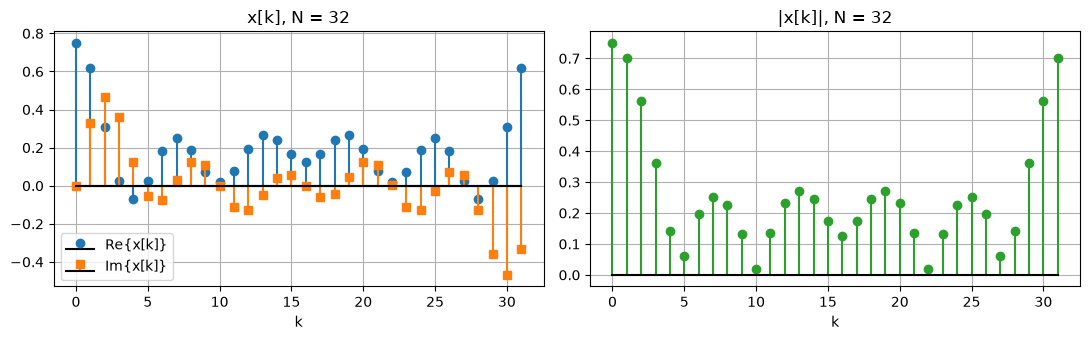

In [9]:
for N in N_values:
    x, _, _, _ = results[N]
    k = np.arange(N)

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].stem(k, x.real, linefmt="C0-", markerfmt="C0o",
               basefmt="k-", label="Re{x[k]}")
    ax[0].stem(k, x.imag, linefmt="C1-", markerfmt="C1s",
               basefmt="k-", label="Im{x[k]}")
    ax[0].set_title(f"x[k], N = {N}")
    ax[0].set_xlabel("k")
    ax[0].legend()
    ax[0].grid(True)

    ax[1].stem(k, np.abs(x), linefmt="C2-", markerfmt="C2o", basefmt="k-")
    ax[1].set_title(f"|x[k]|, N = {N}")
    ax[1].set_xlabel("k")
    ax[1].grid(True)

    fig.tight_layout()
    fig.savefig(figures / f"signal_N{N}.png", dpi=150)
    plt.show()

## Comparison of all $N$

For $N \ge 6$ all non-zero coefficients are kept, so

$$x_N[k] = \frac{1}{N}\sum_{\mu=0}^{5} X[\mu]\,\mathrm{e}^{+\mathrm{j}2\pi\mu\frac{k}{N}}.$$

Every $x_N[k]$ is therefore $\frac{1}{N}$ times the same periodic function sampled at $t = k/N$. Plotting $N \cdot x_N[k]$ over $k/N$ puts all signals on one curve.

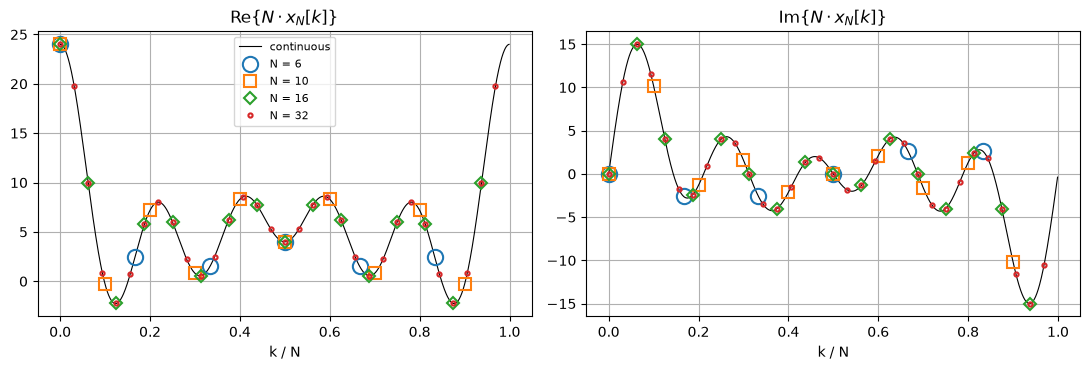

In [10]:
t = np.linspace(0, 1, 1000, endpoint=False)
s = sum(X[m] * np.exp(1j * 2 * np.pi * m * t) for m in range(N0))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(t, s.real, "k-", lw=0.8, label="continuous")
ax[1].plot(t, s.imag, "k-", lw=0.8)
styles = {6: ("o", 11), 10: ("s", 8), 16: ("D", 6), 32: (".", 6)}
for i, N in enumerate(N_values):
    x, _, _, _ = results[N]
    marker, size = styles[N]
    for a, values in zip(ax, [N * x.real, N * x.imag]):
        label = f"N = {N}" if a is ax[0] else None
        a.plot(np.arange(N) / N, values, marker, ms=size, mfc="none",
               mew=1.5, color=f"C{i}", label=label)
ax[0].set_title(r"Re{$N \cdot x_N[k]$}")
ax[1].set_title(r"Im{$N \cdot x_N[k]$}")
for a in ax:
    a.set_xlabel("k / N")
    a.grid(True)
ax[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(figures / "comparison.png", dpi=150)
plt.show()

In [11]:
print(" N   mean(x)   x[0]   max|x|")
for N in N_values:
    x, _, _, _ = results[N]
    mean, first, peak = x.mean().real, x[0].real, np.abs(x).max()
    print(f"{N:2d}   {mean:6.3f}  {first:6.3f}  {peak:6.3f}")

 N   mean(x)   x[0]   max|x|
 6    1.000   4.000   4.000
10    0.600   2.400   2.400
16    0.375   1.500   1.500
32    0.187   0.750   0.750


## Conclusions

1. The synthesized signal is complex. A real signal would need $X[N-\mu] = X^*[\mu]$, and $\mathbf{x}_\mu$ of variant 11 has non-zero values only for $\mu = 0, \dots, 5$.
2. The mean value of $x[k]$ equals $X[0]/N$ (the DC component): $1$ for $N = 6$, $0.6$ for $N = 10$, $0.375$ for $N = 16$ and $0.1875$ for $N = 32$.
3. $x[0] = \frac{1}{N}\sum_\mu X[\mu] = 24/N$. It is the largest value of $|x[k]|$, because at $k = 0$ all eigensignals equal $1$ and add up in phase.
4. Increasing $N$ (extending $\mathbf{x}_\mu$ with zeros) does not change the shape of the signal. It gives more samples of the same period and scales the amplitude by $1/N$.
5. $N$ cannot be smaller than $6$, otherwise some of the non-zero coefficients of $\mathbf{x}_\mu$ would be lost.
6. Because all $X[\mu]$ are real, $x[N-k] = x^*[k]$: the real part is symmetric and the imaginary part is antisymmetric around $k = N/2$ (see the plot for $N = 10$).